In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
CUDA available: False


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Seed:", SEED)

Seed: 42


In [4]:
DATASET_ROOT = "/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test"

TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VAL_DIR   = os.path.join(DATASET_ROOT, "val")
TEST_DIR  = os.path.join(DATASET_ROOT, "test")

print("Train:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Test:", TEST_DIR)

print("\nTrain exists:", os.path.exists(TRAIN_DIR))
print("Validation exists:", os.path.exists(VAL_DIR))
print("Test exists:", os.path.exists(TEST_DIR))

Train: /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/train
Validation: /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/val
Test: /content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/test

Train exists: True
Validation exists: True
Test exists: True


In [5]:
import os

def get_landmark_classes(split_dir):

    classes = set()

    for district in os.listdir(split_dir):

        district_path = os.path.join(split_dir, district)

        if not os.path.isdir(district_path):
            continue

        for landmark in os.listdir(district_path):

            landmark_path = os.path.join(
                district_path,
                landmark
            )

            if os.path.isdir(landmark_path):
                classes.add(landmark)

    return sorted(classes)


train_classes = get_landmark_classes(TRAIN_DIR)
val_classes   = get_landmark_classes(VAL_DIR)
test_classes  = get_landmark_classes(TEST_DIR)

print("Train landmark classes:", len(train_classes))
print("Validation landmark classes:", len(val_classes))
print("Test landmark classes:", len(test_classes))

assert train_classes == val_classes == test_classes, \
    "Train/Val/Test landmark classes do not match!"

CLASS_NAMES = train_classes
NUM_CLASSES = len(CLASS_NAMES)

print("\nNumber of landmark classes:", NUM_CLASSES)

for i, name in enumerate(CLASS_NAMES):
    print(f"{i:2d}: {name}")

Train landmark classes: 58
Validation landmark classes: 58
Test landmark classes: 58

Number of landmark classes: 58
 0: Adinath_Temple
 1: Alutila_Cave
 2: Anderkilla_Shahi_Jame_Mosque
 3: Anderson_Canal
 4: Arifail_Mosque
 5: Bajra_Shahi_Mosque
 6: Banshbaria_Beach
 7: Batali_Hill
 8: Bayazid_Bostami_Shrine
 9: Boga_Lake
10: Central_Railway_Building
11: Chandanpura_Mosque
12: Chandpur_Stadium
13: Chandranath_Hill
14: Chandranath_Temple
15: Chattogram_Central_Shaheed_Minar
16: Chattogram_Court_Building
17: Chattogram_Railway_Station
18: Chattogram_War_Cemetery
19: Chattogram_Zoo
20: Cheragi_Pahar
21: Chimbuk_Hill
22: Comilla_Cantonment_War_Cemetery
23: Coxs_Bazar_Beach
24: Dalal_Bazar_Jamindar_Bari
25: Dharmasagar_Dighi
26: Dulahazara_Safari_Park
27: Ethnological_Museum
28: Foys_Lake
29: Golden_Temple_Bandarban
30: Guliakhali_Beach
31: Haripur_Barendra_Bari
32: Himchari
33: Inani_Beach
34: Itakhola_Mura
35: Jamboree_Park
36: Kalurghat_Bridge
37: Kaptai_Lake
38: Keokradong
39: Kutubdia

In [6]:
def count_images_in_split(split_dir):

    result = {}

    extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".webp"
    )

    for district in os.listdir(split_dir):

        district_path = os.path.join(
            split_dir,
            district
        )

        if not os.path.isdir(district_path):
            continue

        for landmark in os.listdir(district_path):

            landmark_path = os.path.join(
                district_path,
                landmark
            )

            if not os.path.isdir(landmark_path):
                continue

            count = 0

            for file in os.listdir(landmark_path):

                if file.lower().endswith(extensions):
                    count += 1

            result[landmark] = count

    return result


train_counts = count_images_in_split(TRAIN_DIR)
val_counts   = count_images_in_split(VAL_DIR)
test_counts  = count_images_in_split(TEST_DIR)

print("Train images:", sum(train_counts.values()))
print("Validation images:", sum(val_counts.values()))
print("Test images:", sum(test_counts.values()))

print("\nNumber of classes:")
print("Train:", len(train_counts))
print("Val:", len(val_counts))
print("Test:", len(test_counts))

Train images: 1488
Validation images: 321
Test images: 328

Number of classes:
Train: 58
Val: 58
Test: 58


In [7]:
import os

print("=" * 70)
print("CHECKING DATASET STRUCTURE")
print("=" * 70)

for district in sorted(os.listdir(TRAIN_DIR)):

    district_path = os.path.join(TRAIN_DIR, district)

    if not os.path.isdir(district_path):
        continue

    landmarks = [
        x for x in os.listdir(district_path)
        if os.path.isdir(os.path.join(district_path, x))
    ]

    print(f"\n{district}: {len(landmarks)} landmarks")

    for landmark in sorted(landmarks)[:5]:
        landmark_path = os.path.join(district_path, landmark)

        images = [
            f for f in os.listdir(landmark_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]

        print(f"   {landmark}: {len(images)} images")

CHECKING DATASET STRUCTURE

Bandarban: 6 landmarks
   Boga_Lake: 28 images
   Chimbuk_Hill: 24 images
   Golden_Temple_Bandarban: 24 images
   Keokradong: 27 images
   Nilachal: 28 images

Brahmanbaria: 4 landmarks
   Anderson_Canal: 26 images
   Arifail_Mosque: 22 images
   Haripur_Barendra_Bari: 25 images
   Titas_River: 25 images

Chandpur: 1 landmarks
   Chandpur_Stadium: 25 images

Chattogram: 22 landmarks
   Anderkilla_Shahi_Jame_Mosque: 28 images
   Banshbaria_Beach: 24 images
   Batali_Hill: 28 images
   Bayazid_Bostami_Shrine: 28 images
   Central_Railway_Building: 27 images

Coxs_Bazar: 8 landmarks
   Adinath_Temple: 28 images
   Coxs_Bazar_Beach: 27 images
   Dulahazara_Safari_Park: 27 images
   Himchari: 25 images
   Inani_Beach: 27 images

Cumilla: 7 landmarks
   Comilla_Cantonment_War_Cemetery: 25 images
   Dharmasagar_Dighi: 28 images
   Itakhola_Mura: 27 images
   Lalmai_Hills: 26 images
   Mainamati_Museum: 26 images

Khagrachhari: 2 landmarks
   Alutila_Cave: 23 image

In [8]:
print("=" * 70)
print("VERIFYING LANDMARK CONSISTENCY")
print("=" * 70)

print("Train classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Test classes:", len(test_classes))

missing_from_val = sorted(set(train_classes) - set(val_classes))
missing_from_test = sorted(set(train_classes) - set(test_classes))

extra_in_val = sorted(set(val_classes) - set(train_classes))
extra_in_test = sorted(set(test_classes) - set(train_classes))

print("\nMissing from validation:")
print(missing_from_val)

print("\nMissing from test:")
print(missing_from_test)

print("\nExtra in validation:")
print(extra_in_val)

print("\nExtra in test:")
print(extra_in_test)

assert not missing_from_val
assert not missing_from_test
assert not extra_in_val
assert not extra_in_test

print("\n✓ All landmark classes are consistent.")

VERIFYING LANDMARK CONSISTENCY
Train classes: 58
Validation classes: 58
Test classes: 58

Missing from validation:
[]

Missing from test:
[]

Extra in validation:
[]

Extra in test:
[]

✓ All landmark classes are consistent.


In [9]:
print("=" * 70)
print("DATASET STRUCTURE CHECK")
print("=" * 70)

for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VAL", VAL_DIR),
    ("TEST", TEST_DIR)
]:
    print(f"\n{'='*20} {split_name} {'='*20}")

    for district in sorted(os.listdir(split_dir)):
        district_path = os.path.join(split_dir, district)

        if not os.path.isdir(district_path):
            continue

        landmark_folders = [
            x for x in os.listdir(district_path)
            if os.path.isdir(os.path.join(district_path, x))
        ]

        print(f"{district}: {len(landmark_folders)} landmark folders")

        if landmark_folders:
            landmark = sorted(landmark_folders)[0]
            landmark_path = os.path.join(district_path, landmark)

            images = [
                f for f in os.listdir(landmark_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".webp")
                )
            ]

            print(f"   Example: {landmark} → {len(images)} images")

DATASET STRUCTURE CHECK

==================== TRAIN ====================
Bandarban: 6 landmark folders
   Example: Boga_Lake → 28 images
Brahmanbaria: 4 landmark folders
   Example: Anderson_Canal → 26 images
Chandpur: 1 landmark folders
   Example: Chandpur_Stadium → 25 images
Chattogram: 22 landmark folders
   Example: Anderkilla_Shahi_Jame_Mosque → 28 images
Coxs_Bazar: 8 landmark folders
   Example: Adinath_Temple → 28 images
Cumilla: 7 landmark folders
   Example: Comilla_Cantonment_War_Cemetery → 25 images
Khagrachhari: 2 landmark folders
   Example: Alutila_Cave → 23 images
Lakshmipur: 2 landmark folders
   Example: Dalal_Bazar_Jamindar_Bari → 24 images
Noakhali: 2 landmark folders
   Example: Bajra_Shahi_Mosque → 22 images
Rangamati: 4 landmark folders
   Example: Kaptai_Lake → 27 images

==================== VAL ====================
Bandarban: 6 landmark folders
   Example: Boga_Lake → 6 images
Brahmanbaria: 4 landmark folders
   Example: Anderson_Canal → 6 images
Chandpur: 1 

In [10]:
from collections import defaultdict
import os
import pandas as pd

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".webp")

def count_images_by_landmark(split_dir):
    counts = defaultdict(int)

    for district in sorted(os.listdir(split_dir)):
        district_path = os.path.join(split_dir, district)

        if not os.path.isdir(district_path):
            continue

        for landmark in sorted(os.listdir(district_path)):
            landmark_path = os.path.join(district_path, landmark)

            if not os.path.isdir(landmark_path):
                continue

            for filename in os.listdir(landmark_path):
                if filename.lower().endswith(IMAGE_EXTENSIONS):
                    counts[landmark] += 1

    return pd.Series(counts).sort_index()


train_counts = count_images_by_landmark(TRAIN_DIR)
val_counts   = count_images_by_landmark(VAL_DIR)
test_counts  = count_images_by_landmark(TEST_DIR)

print("=" * 70)
print("IMAGE COUNT SUMMARY")
print("=" * 70)

print(f"Train images:      {train_counts.sum()}")
print(f"Validation images: {val_counts.sum()}")
print(f"Test images:       {test_counts.sum()}")

print(
    f"Total images:      "
    f"{train_counts.sum() + val_counts.sum() + test_counts.sum()}"
)

print(f"\nTrain classes: {len(train_counts)}")
print(f"Val classes:   {len(val_counts)}")
print(f"Test classes:  {len(test_counts)}")

IMAGE COUNT SUMMARY
Train images:      1488
Validation images: 321
Test images:       328
Total images:      2137

Train classes: 58
Val classes:   58
Test classes:  58


In [11]:
print("=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

distribution = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
}).fillna(0).astype(int)

distribution["Total"] = (
    distribution["Train"] +
    distribution["Validation"] +
    distribution["Test"]
)

print(distribution.to_string())

print("\nSummary:")
print(distribution.describe())

CLASS DISTRIBUTION
                                  Train  Validation  Test  Total
Adinath_Temple                       28           6     6     40
Alutila_Cave                         23           5     5     33
Anderkilla_Shahi_Jame_Mosque         28           6     6     40
Anderson_Canal                       26           6     5     37
Arifail_Mosque                       22           5     4     31
Bajra_Shahi_Mosque                   22           5     5     32
Banshbaria_Beach                     24           5     6     35
Batali_Hill                          28           6     6     40
Bayazid_Bostami_Shrine               28           6     6     40
Boga_Lake                            28           6     6     40
Central_Railway_Building             27           6     6     39
Chandanpura_Mosque                   24           5     6     35
Chandpur_Stadium                     25           5     6     36
Chandranath_Hill                     24           5     6     35
Chandr

In [12]:
missing_train = distribution[distribution["Train"] == 0]
missing_val   = distribution[distribution["Validation"] == 0]
missing_test  = distribution[distribution["Test"] == 0]

print("Classes missing from train:", len(missing_train))
print("Classes missing from val:  ", len(missing_val))
print("Classes missing from test: ", len(missing_test))

Classes missing from train: 0
Classes missing from val:   0
Classes missing from test:  0


In [13]:
train_classes = set(train_counts.index)
val_classes   = set(val_counts.index)
test_classes  = set(test_counts.index)

print("Train classes:", len(train_classes))
print("Val classes:  ", len(val_classes))
print("Test classes: ", len(test_classes))

print("\nMissing from train:", sorted(
    val_classes.union(test_classes) - train_classes
))

print("Missing from val:", sorted(
    train_classes.union(test_classes) - val_classes
))

print("Missing from test:", sorted(
    train_classes.union(val_classes) - test_classes
))

assert train_classes == val_classes == test_classes, \
    "ERROR: Train/Val/Test classes are not identical!"

CLASS_NAMES = sorted(train_classes)
NUM_CLASSES = len(CLASS_NAMES)

print("\nFinal number of landmark classes:", NUM_CLASSES)

Train classes: 58
Val classes:   58
Test classes:  58

Missing from train: []
Missing from val: []
Missing from test: []

Final number of landmark classes: 58


In [14]:
print("=" * 70)
print("DATASET STRUCTURE CHECK")
print("=" * 70)

for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR),
    ("TEST", TEST_DIR)
]:

    print(f"\n{'='*20} {split_name} {'='*20}")

    for district in sorted(os.listdir(split_dir)):

        district_path = os.path.join(split_dir, district)

        if not os.path.isdir(district_path):
            continue

        landmarks = [
            x for x in os.listdir(district_path)
            if os.path.isdir(os.path.join(district_path, x))
        ]

        print(f"\n{district}: {len(landmarks)} landmarks")

        for landmark in sorted(landmarks)[:3]:

            landmark_path = os.path.join(
                district_path,
                landmark
            )

            images = [
                f for f in os.listdir(landmark_path)
                if f.lower().endswith(IMAGE_EXTENSIONS)
            ]

            print(
                f"   {landmark}: {len(images)} images"
            )

DATASET STRUCTURE CHECK

==================== TRAIN ====================

Bandarban: 6 landmarks
   Boga_Lake: 28 images
   Chimbuk_Hill: 24 images
   Golden_Temple_Bandarban: 24 images

Brahmanbaria: 4 landmarks
   Anderson_Canal: 26 images
   Arifail_Mosque: 22 images
   Haripur_Barendra_Bari: 25 images

Chandpur: 1 landmarks
   Chandpur_Stadium: 25 images

Chattogram: 22 landmarks
   Anderkilla_Shahi_Jame_Mosque: 28 images
   Banshbaria_Beach: 24 images
   Batali_Hill: 28 images

Coxs_Bazar: 8 landmarks
   Adinath_Temple: 28 images
   Coxs_Bazar_Beach: 27 images
   Dulahazara_Safari_Park: 27 images

Cumilla: 7 landmarks
   Comilla_Cantonment_War_Cemetery: 25 images
   Dharmasagar_Dighi: 28 images
   Itakhola_Mura: 27 images

Khagrachhari: 2 landmarks
   Alutila_Cave: 23 images
   Mong_King_Palace: 26 images

Lakshmipur: 2 landmarks
   Dalal_Bazar_Jamindar_Bari: 24 images
   Ramgati_Beach: 26 images

Noakhali: 2 landmarks
   Bajra_Shahi_Mosque: 22 images
   Nijhum_Dwip: 24 images

Ra

In [15]:
from torch.utils.data import Dataset

class LandmarkDataset(Dataset):

    def __init__(
        self,
        root_dir,
        class_names,
        transform=None
    ):

        self.root_dir = root_dir
        self.class_names = class_names

        self.class_to_idx = {
            name: idx
            for idx, name in enumerate(class_names)
        }

        self.transform = transform
        self.samples = []

        valid_extensions = (
            ".jpg",
            ".jpeg",
            ".png",
            ".webp"
        )

        for district in sorted(os.listdir(root_dir)):

            district_path = os.path.join(
                root_dir,
                district
            )

            if not os.path.isdir(district_path):
                continue

            for landmark in sorted(os.listdir(district_path)):

                landmark_path = os.path.join(
                    district_path,
                    landmark
                )

                if not os.path.isdir(landmark_path):
                    continue

                if landmark not in self.class_to_idx:
                    continue

                label = self.class_to_idx[landmark]

                for filename in sorted(
                    os.listdir(landmark_path)
                ):

                    if not filename.lower().endswith(
                        valid_extensions
                    ):
                        continue

                    image_path = os.path.join(
                        landmark_path,
                        filename
                    )

                    self.samples.append(
                        (image_path, label)
                    )

        print(
            f"{root_dir} → "
            f"{len(self.samples)} images"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [16]:
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.75, 1.0),
        ratio=(0.85, 1.15)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.15,
        hue=0.03
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),

    transforms.RandomErasing(
        p=0.15,
        scale=(0.02, 0.10),
        ratio=(0.3, 3.3),
        value="random"
    )
])


val_test_transform = transforms.Compose([

    transforms.Resize(256),

    transforms.CenterCrop(
        IMG_SIZE
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [17]:
train_dataset = LandmarkDataset(
    TRAIN_DIR,
    CLASS_NAMES,
    transform=train_transform
)

val_dataset = LandmarkDataset(
    VAL_DIR,
    CLASS_NAMES,
    transform=val_test_transform
)

test_dataset = LandmarkDataset(
    TEST_DIR,
    CLASS_NAMES,
    transform=val_test_transform
)

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/train → 1488 images
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/val → 321 images
/content/drive/MyDrive/Chattogram_Landmark_Dataset/06_train_val_test/test → 328 images

Dataset sizes:
Train: 1488
Validation: 321
Test: 328


In [18]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [19]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([42,  7, 10,  1,  0, 27,  1, 43, 50, 33])


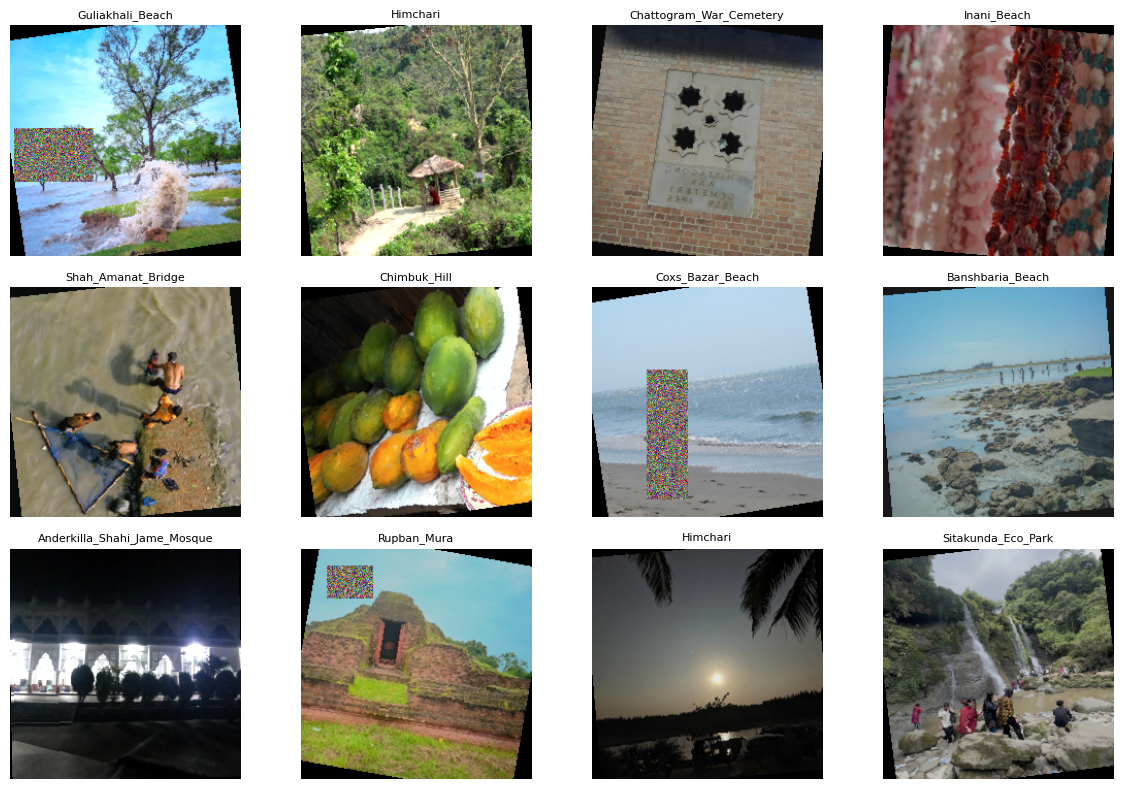

In [20]:
import matplotlib.pyplot as plt
import numpy as np

def denormalize(image):

    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    image = image.numpy().transpose(
        1, 2, 0
    )

    image = image * std + mean

    return np.clip(image, 0, 1)


images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(min(12, len(images))):

    plt.subplot(3, 4, i + 1)

    image = denormalize(
        images[i].cpu()
    )

    plt.imshow(image)

    class_name = CLASS_NAMES[
        labels[i].item()
    ]

    plt.title(class_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
from torchvision import models
import torch.nn as nn

weights = models.MobileNet_V3_Large_Weights.DEFAULT

model = models.mobilenet_v3_large(
    weights=weights
)

print(model)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 118MB/s]


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

In [22]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cpu


In [23]:
# Recreate the same pretrained architecture before replacing the classifier.
model = models.mobilenet_v3_large(
    weights=models.MobileNet_V3_Large_Weights.DEFAULT
)


In [24]:
# MobileNetV3-Large's final classifier layer is classifier[3].
in_features = model.classifier[3].in_features

model.classifier[3] = nn.Sequential(
    nn.Dropout(p=0.40),
    nn.Linear(in_features, NUM_CLASSES)
)

model = model.to(device)

print("MobileNetV3-Large classifier replaced.")
print("Number of classes:", NUM_CLASSES)


MobileNetV3-Large classifier replaced.
Number of classes: 58


In [25]:
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 4276330
Trainable parameters: 1304378


In [26]:
criterion = nn.CrossEntropyLoss(
    label_smoothing=0.10
)

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [27]:
optimizer = optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=1e-3,

    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="max",

    factor=0.5,

    patience=2,

    min_lr=1e-6
)

print("Optimizer and scheduler ready.")

Optimizer and scheduler ready.


In [28]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_acc = (
        correct / total
    )

    return epoch_loss, epoch_acc

In [29]:
@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        running_loss += (
            loss.item() *
            images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_acc = (
        correct / total
    )

    return epoch_loss, epoch_acc

In [30]:
MODEL_DIR = (
    "/content/drive/MyDrive/"
    "Chattogram_Landmark_Dataset/"
    "07_models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Model directory:")
print(MODEL_DIR)


Model directory:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models


In [31]:
STAGE1_EPOCHS = 8
PATIENCE = 3

best_val_acc = 0.0
patience_counter = 0

stage1_history = []

stage1_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Stage1_Best.pth"
)

for epoch in range(
    STAGE1_EPOCHS
):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    stage1_history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_loss,

        "val_accuracy": val_acc,

        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch+1}/{STAGE1_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        patience_counter = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "class_names":
                    CLASS_NAMES,

                "num_classes":
                    NUM_CLASSES,

                "epoch":
                    epoch + 1,

                "val_accuracy":
                    val_acc
            },
            stage1_path
        )

        print(
            "   ✓ Best Stage 1 model saved."
        )

    else:

        patience_counter += 1

        print(
            f"   No improvement "
            f"({patience_counter}/{PATIENCE})"
        )

        if patience_counter >= PATIENCE:

            print(
                "\nEarly stopping Stage 1."
            )

            break

print("\nStage 1 complete.")
print("Best validation accuracy:", best_val_acc)
print("Saved:", stage1_path)

Epoch 1/8 | Train Loss: 3.6482 | Train Acc: 0.1720 | Val Loss: 3.0818 | Val Acc: 0.3364 | LR: 1.00e-03
   ✓ Best Stage 1 model saved.
Epoch 2/8 | Train Loss: 2.6487 | Train Acc: 0.4375 | Val Loss: 2.7133 | Val Acc: 0.3988 | LR: 1.00e-03
   ✓ Best Stage 1 model saved.
Epoch 3/8 | Train Loss: 2.2440 | Train Acc: 0.5349 | Val Loss: 2.5998 | Val Acc: 0.4237 | LR: 1.00e-03
   ✓ Best Stage 1 model saved.
Epoch 4/8 | Train Loss: 1.9985 | Train Acc: 0.6149 | Val Loss: 2.5095 | Val Acc: 0.4579 | LR: 1.00e-03
   ✓ Best Stage 1 model saved.
Epoch 5/8 | Train Loss: 1.7941 | Train Acc: 0.6828 | Val Loss: 2.5012 | Val Acc: 0.4673 | LR: 1.00e-03
   ✓ Best Stage 1 model saved.
Epoch 6/8 | Train Loss: 1.6824 | Train Acc: 0.7083 | Val Loss: 2.5050 | Val Acc: 0.4766 | LR: 1.00e-03
   ✓ Best Stage 1 model saved.
Epoch 7/8 | Train Loss: 1.5327 | Train Acc: 0.7749 | Val Loss: 2.5151 | Val Acc: 0.4704 | LR: 1.00e-03
   No improvement (1/3)
Epoch 8/8 | Train Loss: 1.4923 | Train Acc: 0.7870 | Val Loss: 2.5117

In [32]:
checkpoint = torch.load(
    stage1_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    "Loaded best Stage 1 model."
)

print(
    "Best Stage 1 validation accuracy:",
    checkpoint["val_accuracy"]
)

Loaded best Stage 1 model.
Best Stage 1 validation accuracy: 0.4766355140186916


In [33]:
# Freeze everything first

for param in model.features.parameters():
    param.requires_grad = False


# Unfreeze only the final feature block

for param in model.features[-1].parameters():
    param.requires_grad = True


# Classifier remains trainable

for param in model.classifier.parameters():
    param.requires_grad = True


trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters after fine-tuning:",
    trainable_params
)

Trainable parameters after fine-tuning: 1459898


In [34]:
optimizer = optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=1e-4,

    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="max",

    factor=0.5,

    patience=2,

    min_lr=1e-7
)

print("Stage 2 optimizer ready.")

Stage 2 optimizer ready.


In [35]:
STAGE2_EPOCHS = 12
PATIENCE = 4

best_val_acc = 0.0
patience_counter = 0

stage2_history = []

stage2_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Final_Best.pth"
)

for epoch in range(
    STAGE2_EPOCHS
):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    stage2_history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_loss,

        "val_accuracy": val_acc,

        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch+1}/{STAGE2_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.2e}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        patience_counter = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "class_names":
                    CLASS_NAMES,

                "num_classes":
                    NUM_CLASSES,

                "epoch":
                    epoch + 1,

                "val_accuracy":
                    val_acc
            },
            stage2_path
        )

        print(
            "   ✓ Best final model saved."
        )

    else:

        patience_counter += 1

        print(
            f"   No improvement "
            f"({patience_counter}/{PATIENCE})"
        )

        if patience_counter >= PATIENCE:

            print(
                "\nEarly stopping Stage 2."
            )

            break

print("\nStage 2 complete.")
print(
    "Best validation accuracy:",
    best_val_acc
)

print(
    "Saved:",
    stage2_path
)

Epoch 1/12 | Train Loss: 1.4724 | Train Acc: 0.8091 | Val Loss: 2.4493 | Val Acc: 0.4922 | LR: 1.00e-04
   ✓ Best final model saved.
Epoch 2/12 | Train Loss: 1.4143 | Train Acc: 0.8219 | Val Loss: 2.4401 | Val Acc: 0.4891 | LR: 1.00e-04
   No improvement (1/4)
Epoch 3/12 | Train Loss: 1.3858 | Train Acc: 0.8306 | Val Loss: 2.4350 | Val Acc: 0.4798 | LR: 1.00e-04
   No improvement (2/4)
Epoch 4/12 | Train Loss: 1.3735 | Train Acc: 0.8367 | Val Loss: 2.4331 | Val Acc: 0.4891 | LR: 5.00e-05
   No improvement (3/4)
Epoch 5/12 | Train Loss: 1.3381 | Train Acc: 0.8495 | Val Loss: 2.4278 | Val Acc: 0.4860 | LR: 5.00e-05
   No improvement (4/4)

Early stopping Stage 2.

Stage 2 complete.
Best validation accuracy: 0.49221183800623053
Saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Final_Best.pth


In [36]:
# Combine both stages into one history table for easier comparison with other models.
stage1_df = pd.DataFrame(stage1_history).copy()
stage2_df = pd.DataFrame(stage2_history).copy()

if not stage1_df.empty:
    stage1_df["stage"] = "Stage 1"
    stage1_df["global_epoch"] = stage1_df["epoch"]

if not stage2_df.empty:
    stage2_df["stage"] = "Stage 2"
    offset = int(stage1_df["epoch"].max()) if not stage1_df.empty else 0
    stage2_df["global_epoch"] = stage2_df["epoch"] + offset

history_df = pd.concat(
    [stage1_df, stage2_df],
    ignore_index=True
)

# Standardize column names for cross-model comparisons.
history_df = history_df.rename(columns={
    "train_accuracy": "train_acc",
    "val_accuracy": "val_acc",
    "learning_rate": "learning_rate"
})

history_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Training_History.csv"
)

history_df.to_csv(history_path, index=False)

print("Combined history saved:", history_path)
print(history_df.to_string(index=False))


Combined history saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Training_History.csv
 epoch  train_loss  train_acc  val_loss  val_acc  learning_rate   stage  global_epoch
     1    3.648171   0.172043  3.081788 0.336449        0.00100 Stage 1             1
     2    2.648738   0.437500  2.713255 0.398754        0.00100 Stage 1             2
     3    2.244042   0.534946  2.599789 0.423676        0.00100 Stage 1             3
     4    1.998450   0.614919  2.509479 0.457944        0.00100 Stage 1             4
     5    1.794069   0.682796  2.501231 0.467290        0.00100 Stage 1             5
     6    1.682392   0.708333  2.504966 0.476636        0.00100 Stage 1             6
     7    1.532735   0.774866  2.515086 0.470405        0.00100 Stage 1             7
     8    1.492272   0.786962  2.511676 0.457944        0.00100 Stage 1             8
     1    1.472439   0.809140  2.449253 0.492212        0.00010 Stage 2             9
     2    1.41425

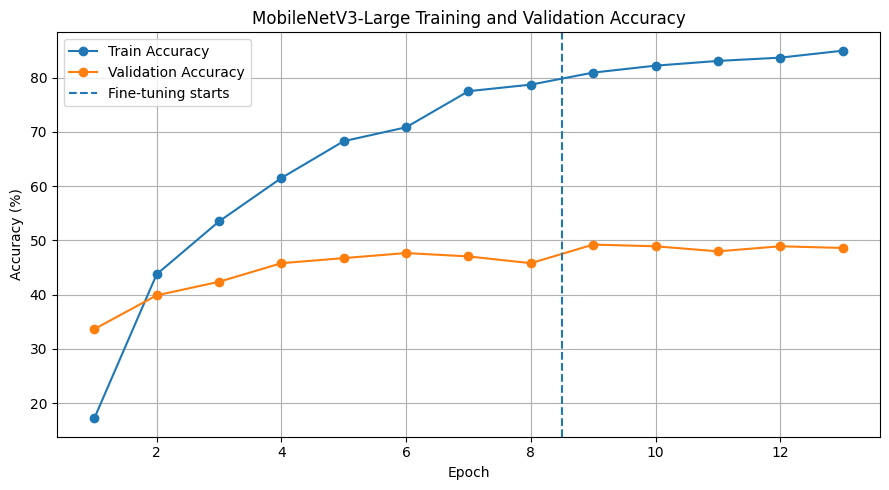

Accuracy plot saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Training_Validation_Accuracy.png


In [37]:
# Plot training and validation accuracy across both stages.
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["global_epoch"],
    history_df["train_acc"] * 100,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    history_df["global_epoch"],
    history_df["val_acc"] * 100,
    marker="o",
    label="Validation Accuracy"
)

# Mark the transition between Stage 1 and Stage 2.
if not stage1_df.empty and not stage2_df.empty:
    plt.axvline(
        x=int(stage1_df["epoch"].max()) + 0.5,
        linestyle="--",
        label="Fine-tuning starts"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MobileNetV3-Large Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_plot_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Training_Validation_Accuracy.png"
)
plt.savefig(accuracy_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Accuracy plot saved:", accuracy_plot_path)


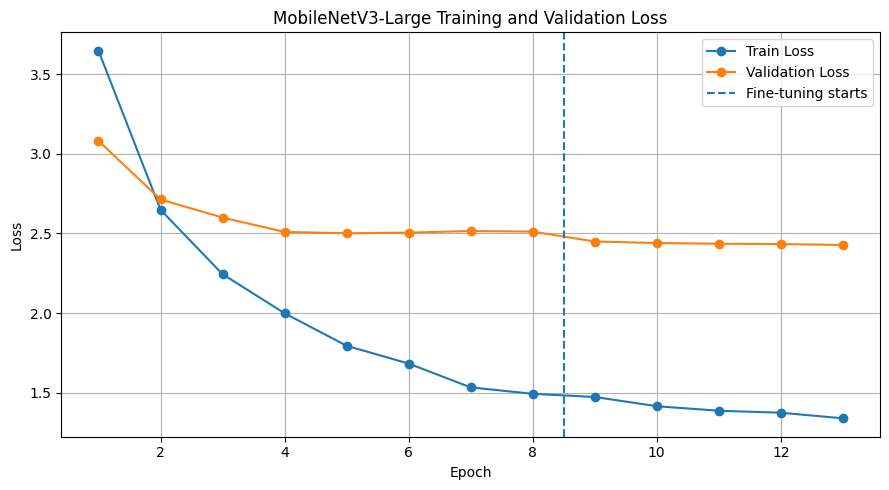

Loss plot saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Training_Validation_Loss.png


In [38]:
# Plot training and validation loss across both stages.
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["global_epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["global_epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

if not stage1_df.empty and not stage2_df.empty:
    plt.axvline(
        x=int(stage1_df["epoch"].max()) + 0.5,
        linestyle="--",
        label="Fine-tuning starts"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3-Large Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_plot_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Training_Validation_Loss.png"
)
plt.savefig(loss_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Loss plot saved:", loss_plot_path)


In [39]:
checkpoint = torch.load(
    stage2_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print(
    "Best final model loaded."
)

print(
    "Best validation accuracy:",
    checkpoint["val_accuracy"]
)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

Best final model loaded.
Best validation accuracy: 0.49221183800623053
Best epoch: 1


In [40]:
test_loss, test_accuracy = validate_one_epoch(
    model,
    test_loader,
    criterion,
    device
)

print("=" * 70)
print("FINAL TEST RESULT")
print("=" * 70)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: {test_accuracy:.4f}"
)

print(
    f"Test Accuracy (%): "
    f"{test_accuracy * 100:.2f}%"
)

FINAL TEST RESULT
Test Loss: 2.4724
Test Accuracy: 0.4817
Test Accuracy (%): 48.17%


In [41]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        predictions = outputs.argmax(
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

print(
    "Number of test samples:",
    len(all_labels)
)

print(
    "Accuracy:",
    accuracy_score(
        all_labels,
        all_predictions
    )
)

Number of test samples: 328
Accuracy: 0.4817073170731707


In [42]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print(
    report_df.to_string()
)

                                  precision    recall  f1-score     support
Adinath_Temple                     0.600000  0.500000  0.545455    6.000000
Alutila_Cave                       0.250000  0.200000  0.222222    5.000000
Anderkilla_Shahi_Jame_Mosque       0.571429  0.666667  0.615385    6.000000
Anderson_Canal                     0.500000  0.400000  0.444444    5.000000
Arifail_Mosque                     1.000000  1.000000  1.000000    4.000000
Bajra_Shahi_Mosque                 1.000000  0.400000  0.571429    5.000000
Banshbaria_Beach                   0.666667  0.333333  0.444444    6.000000
Batali_Hill                        0.363636  0.666667  0.470588    6.000000
Bayazid_Bostami_Shrine             0.250000  0.166667  0.200000    6.000000
Boga_Lake                          0.454545  0.833333  0.588235    6.000000
Central_Railway_Building           1.000000  0.333333  0.500000    6.000000
Chandanpura_Mosque                 0.750000  1.000000  0.857143    6.000000
Chandpur_Sta

In [43]:
report_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Test_Classification_Report.csv"
)

report_df.to_csv(
    report_path
)

print(
    "Saved:",
    report_path
)

Saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Test_Classification_Report.csv


In [44]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(
    "Confusion matrix shape:",
    cm.shape
)

Confusion matrix shape: (58, 58)


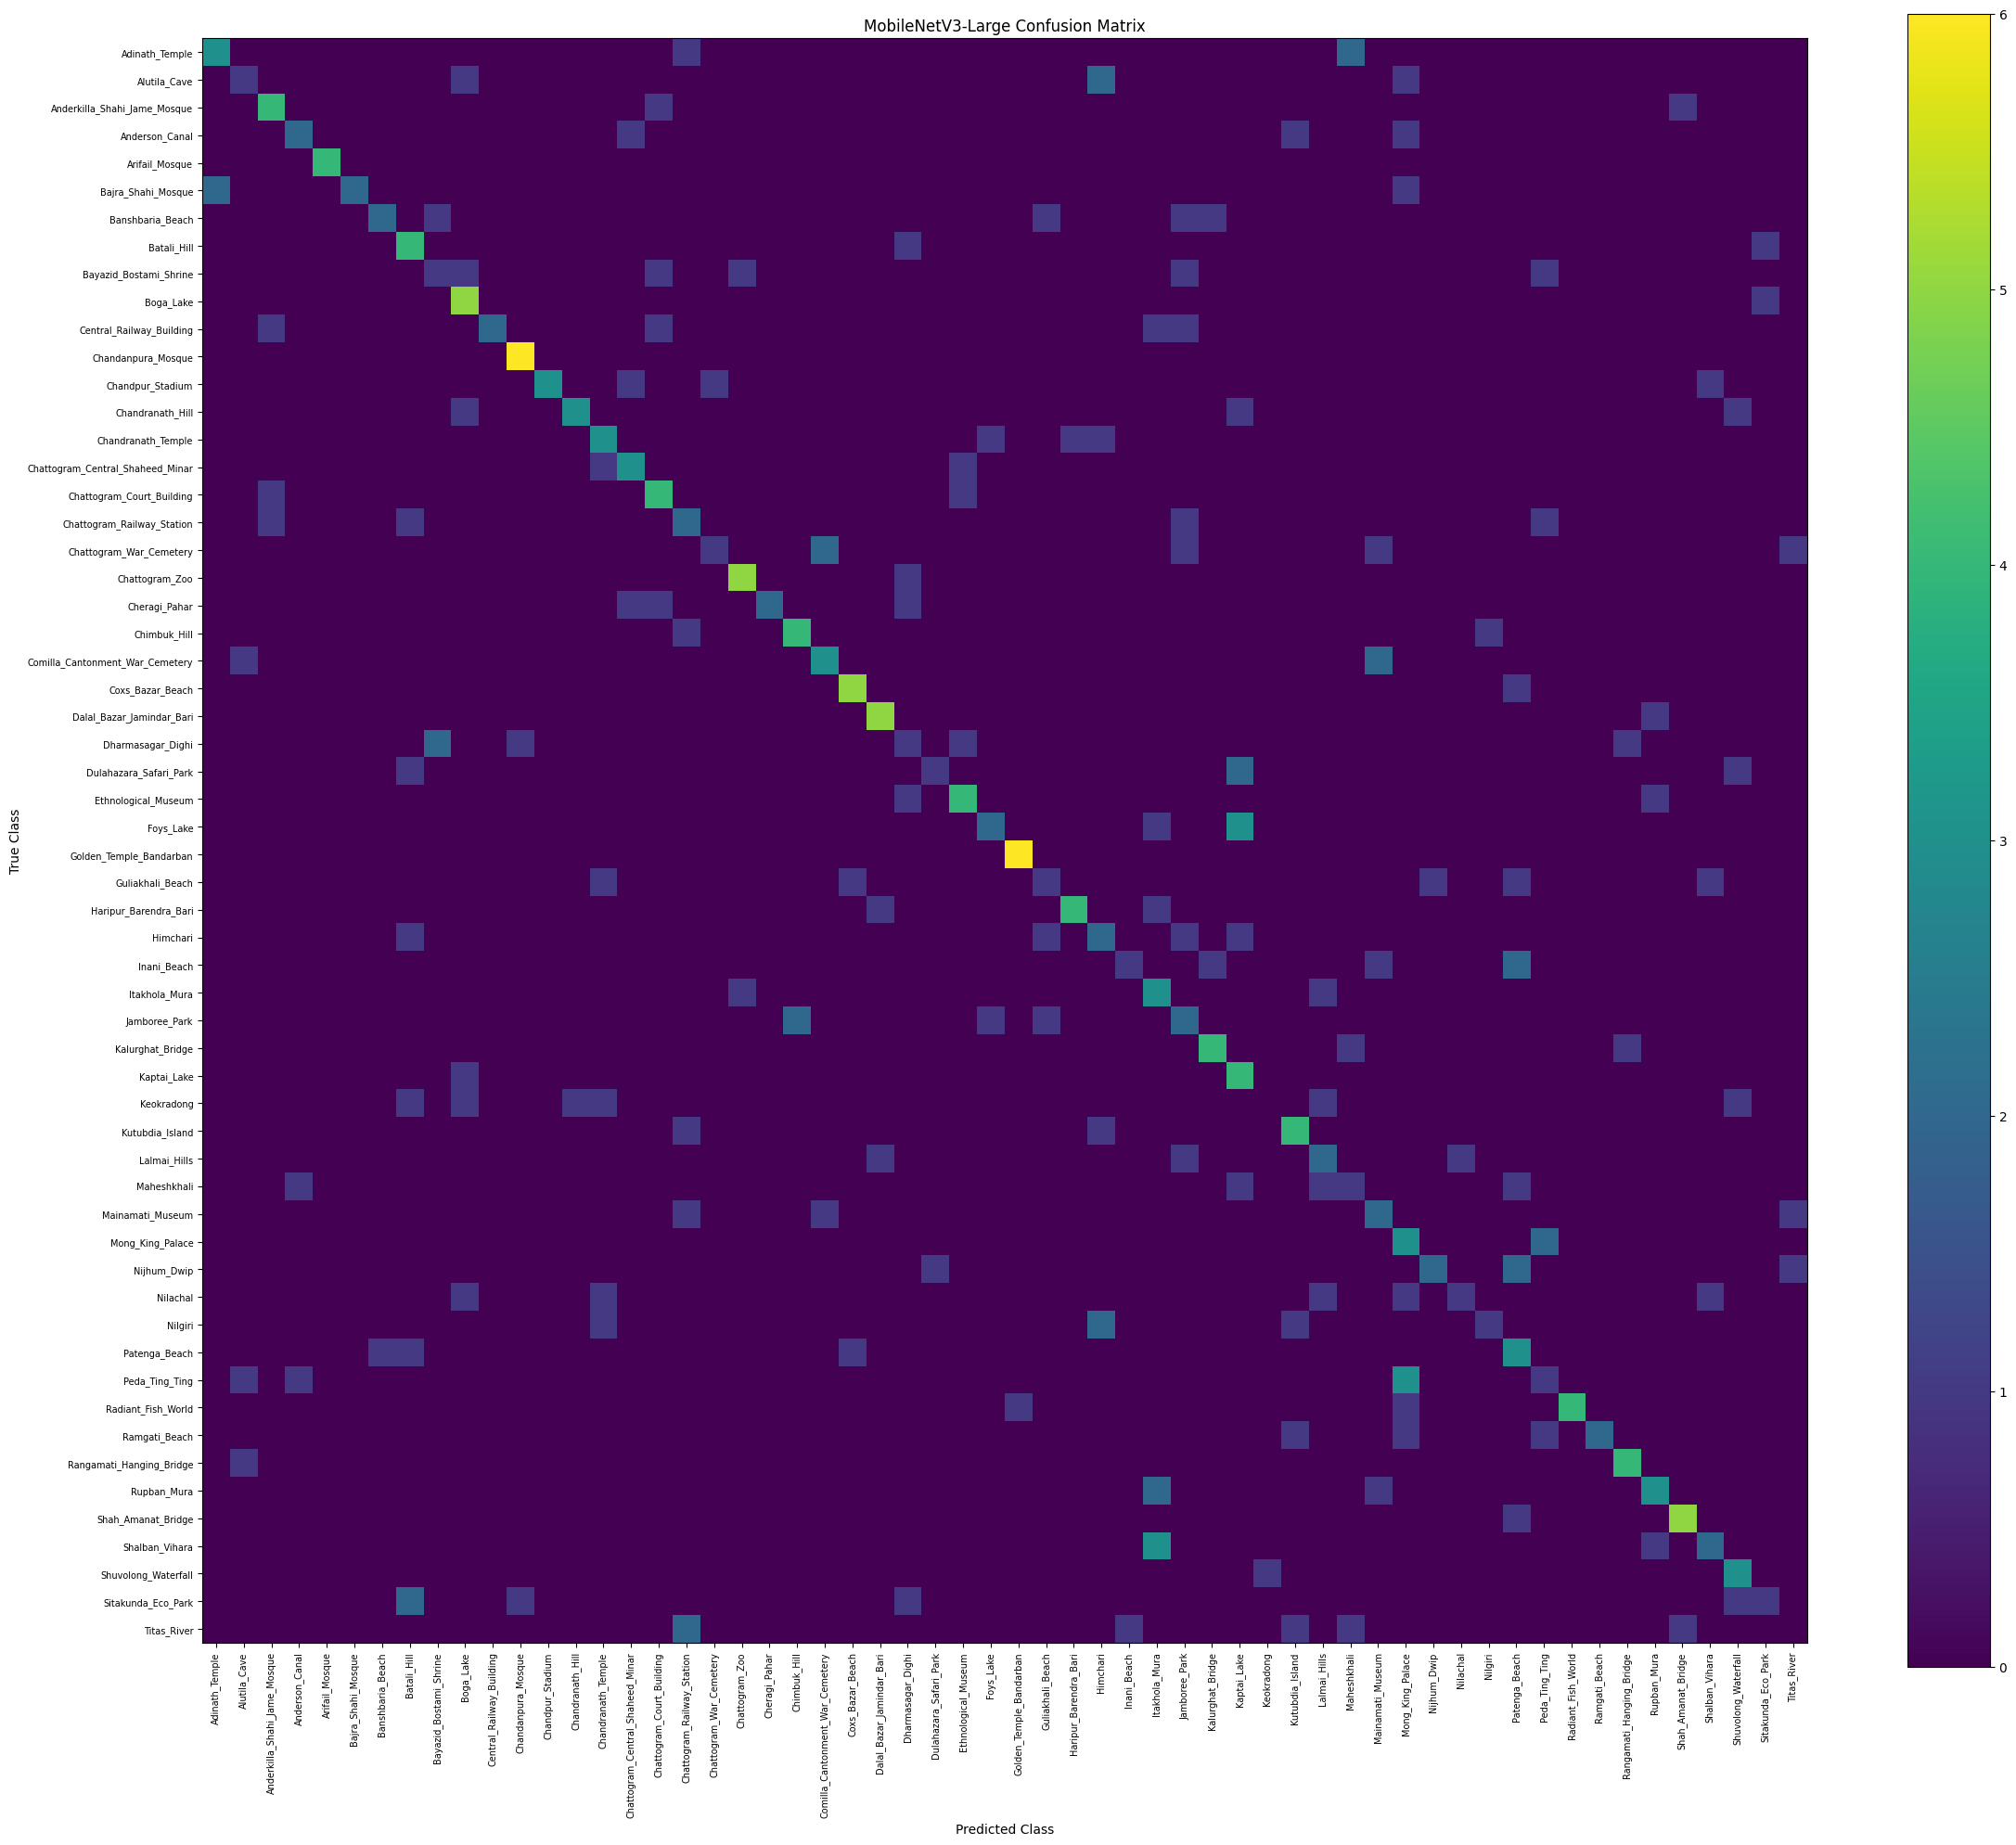

Confusion matrix saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Confusion_Matrix.png


In [45]:
plt.figure(
    figsize=(24, 20)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "MobileNetV3-Large Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    fontsize=7
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()

confusion_matrix_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Confusion_Matrix.png"
)
plt.savefig(confusion_matrix_path, dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix saved:", confusion_matrix_path)

In [46]:
confusion_pairs = []

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        if i == j:
            continue

        count = cm[i, j]

        if count > 0:

            confusion_pairs.append({

                "True_Class":
                    CLASS_NAMES[i],

                "Predicted_Class":
                    CLASS_NAMES[j],

                "Misclassified_Images":
                    int(count)
            })


confusion_pairs_df = pd.DataFrame(
    confusion_pairs
)

if len(confusion_pairs_df) > 0:

    confusion_pairs_df = (
        confusion_pairs_df
        .sort_values(
            "Misclassified_Images",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        confusion_pairs_df.head(30).to_string(
            index=False
        )
    )

else:

    print(
        "No misclassified pairs found."
    )

                     True_Class                 Predicted_Class  Misclassified_Images
                      Foys_Lake                     Kaptai_Lake                     3
                 Shalban_Vihara                   Itakhola_Mura                     3
                 Peda_Ting_Ting                Mong_King_Palace                     3
                   Alutila_Cave                        Himchari                     2
                 Adinath_Temple                     Maheshkhali                     2
         Dulahazara_Safari_Park                     Kaptai_Lake                     2
             Sitakunda_Eco_Park                     Batali_Hill                     2
                  Jamboree_Park                    Chimbuk_Hill                     2
                    Nijhum_Dwip                   Patenga_Beach                     2
                        Nilgiri                        Himchari                     2
                    Rupban_Mura                   Itak

In [47]:
confusion_pairs_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Confusion_Pairs.csv"
)

confusion_pairs_df.to_csv(
    confusion_pairs_path,
    index=False
)

print(
    "Saved:",
    confusion_pairs_path
)

Saved: /content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Confusion_Pairs.csv


In [48]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 70)
print("FINAL METRICS")
print("=" * 70)

print(
    f"Accuracy:        {test_accuracy:.4f}"
)

print(
    f"Macro Precision: {macro_precision:.4f}"
)

print(
    f"Macro Recall:    {macro_recall:.4f}"
)

print(
    f"Macro F1:        {macro_f1:.4f}"
)

print(
    f"Weighted F1:     {weighted_f1:.4f}"
)

FINAL METRICS
Accuracy:        0.4817
Macro Precision: 0.5207
Macro Recall:    0.4836
Macro F1:        0.4714
Weighted F1:     0.4706


In [49]:
final_model_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Chattogram_Final.pth"
)

torch.save(
    {
        "model_state_dict":
            model.state_dict(),

        "class_names":
            CLASS_NAMES,

        "num_classes":
            NUM_CLASSES,

        "test_accuracy":
            test_accuracy,

        "macro_precision":
            macro_precision,

        "macro_recall":
            macro_recall,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1
    },
    final_model_path
)

print(
    "Final model saved:"
)

print(
    final_model_path
)

Final model saved:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Chattogram_Final.pth


In [50]:
summary = pd.DataFrame([{

    "Model":
        "MobileNetV3-Large",

    "Dataset":
        "Chattogram Division Landmark Dataset",

    "Number_of_Classes":
        NUM_CLASSES,

    "Train_Images":
        len(train_dataset),

    "Validation_Images":
        len(val_dataset),

    "Test_Images":
        len(test_dataset),

    "Image_Size":
        IMG_SIZE,

    "Batch_Size":
        BATCH_SIZE,

    "Stage1_Max_Epochs":
        STAGE1_EPOCHS,

    "Stage2_Max_Epochs":
        STAGE2_EPOCHS,

    "Test_Accuracy":
        test_accuracy,

    "Macro_Precision":
        macro_precision,

    "Macro_Recall":
        macro_recall,

    "Macro_F1":
        macro_f1,

    "Weighted_F1":
        weighted_f1
}])

summary_path = os.path.join(
    MODEL_DIR,
    "MobileNetV3Large_Experiment_Summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print(
    "Experiment summary saved:"
)

print(
    summary_path
)

Experiment summary saved:
/content/drive/MyDrive/Chattogram_Landmark_Dataset/07_models/MobileNetV3Large_Experiment_Summary.csv


In [51]:
print("=" * 70)
print("SAVED MODEL/RESULT FILES")
print("=" * 70)

for filename in sorted(
    os.listdir(MODEL_DIR)
):

    path = os.path.join(
        MODEL_DIR,
        filename
    )

    if os.path.isfile(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"{filename:<55} "
            f"{size_mb:.2f} MB"
        )

SAVED MODEL/RESULT FILES
MobileNetV3Large_Chattogram_Final.pth                   16.51 MB
MobileNetV3Large_Confusion_Matrix.png                   0.49 MB
MobileNetV3Large_Confusion_Pairs.csv                    0.01 MB
MobileNetV3Large_Experiment_Summary.csv                 0.00 MB
MobileNetV3Large_Final_Best.pth                         16.51 MB
MobileNetV3Large_Stage1_Best.pth                        16.51 MB
MobileNetV3Large_Test_Classification_Report.csv         0.00 MB
MobileNetV3Large_Training_History.csv                   0.00 MB
MobileNetV3Large_Training_Validation_Accuracy.png       0.10 MB
MobileNetV3Large_Training_Validation_Loss.png           0.09 MB
